In [2]:
import sys
!{sys.executable} -m pip install kaggle


   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   ---------------------------------------- 0/2 [jupytext]
   -------------------- ------------------- 1/2 [kaggle]
   -------------------- ------------------- 1/2 [kaggle]
   -------------------- ------------------- 1/2 [kaggle]
   ---------------------------------------- 2/2 [kaggle]



In [1]:
import os, json

# Write credentials file
kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)
with open(os.path.join(kaggle_dir, "kaggle.json"), "w") as f:
    json.dump({"username": "kmader", "key": "KGAT_23d8a8b769dffad67728a18290feffc6"}, f)

# Download dataset
import kaggle
kaggle.api.authenticate()
kaggle.api.dataset_download_files(
    "kmader/skin-cancer-mnist-ham10000",
    path="./data",
    unzip=True
)
print("Downloaded to ./data")

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
Downloaded to ./data


In [1]:
import os

for root, dirs, files in os.walk("./data"):
    for file in files:
        filepath = os.path.join(root, file)
        print(filepath)

./data\HAM10000_metadata.csv
./data\hmnist_28_28_L.csv
./data\hmnist_28_28_RGB.csv
./data\hmnist_8_8_L.csv
./data\hmnist_8_8_RGB.csv
./data\.ipynb_checkpoints\HAM10000_metadata-checkpoint.csv
./data\.ipynb_checkpoints\hmnist_28_28_L-checkpoint.csv
./data\.ipynb_checkpoints\hmnist_28_28_RGB-checkpoint.csv
./data\.ipynb_checkpoints\hmnist_8_8_L-checkpoint.csv
./data\all_images\ISIC_0024306.jpg
./data\all_images\ISIC_0024307.jpg
./data\all_images\ISIC_0024308.jpg
./data\all_images\ISIC_0024309.jpg
./data\all_images\ISIC_0024310.jpg
./data\all_images\ISIC_0024311.jpg
./data\all_images\ISIC_0024312.jpg
./data\all_images\ISIC_0024313.jpg
./data\all_images\ISIC_0024314.jpg
./data\all_images\ISIC_0024315.jpg
./data\all_images\ISIC_0024316.jpg
./data\all_images\ISIC_0024317.jpg
./data\all_images\ISIC_0024318.jpg
./data\all_images\ISIC_0024319.jpg
./data\all_images\ISIC_0024320.jpg
./data\all_images\ISIC_0024321.jpg
./data\all_images\ISIC_0024322.jpg
./data\all_images\ISIC_0024323.jpg
./data\all

In [3]:
import kaggle

kaggle.api.authenticate()
kaggle.api.dataset_download_files(
    "kmader/skin-cancer-mnist-ham10000",
    path="./data",
    unzip=True,
    quiet=False   # shows progress bar
)
print("Done! Downloaded to ./data")

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000


100%|██████████| 5.20G/5.20G [30:34<00:00, 3.04MB/s]  



Done! Downloaded to ./data


In [2]:
import os

for root, dirs, files in os.walk("./data"):
    for file in files:
        filepath = os.path.join(root, file)
        size = os.path.getsize(filepath) / (1024*1024)  # size in MB
        print(f"{filepath}  ({size:.1f} MB)")

./data\HAM10000_metadata.csv  (0.5 MB)
./data\hmnist_28_28_L.csv  (29.4 MB)
./data\hmnist_28_28_RGB.csv  (87.6 MB)
./data\hmnist_8_8_L.csv  (2.4 MB)
./data\hmnist_8_8_RGB.csv  (7.2 MB)
./data\.ipynb_checkpoints\HAM10000_metadata-checkpoint.csv  (0.5 MB)
./data\.ipynb_checkpoints\hmnist_28_28_L-checkpoint.csv  (29.4 MB)
./data\.ipynb_checkpoints\hmnist_28_28_RGB-checkpoint.csv  (87.6 MB)
./data\.ipynb_checkpoints\hmnist_8_8_L-checkpoint.csv  (2.4 MB)
./data\all_images\ISIC_0024306.jpg  (0.3 MB)
./data\all_images\ISIC_0024307.jpg  (0.3 MB)
./data\all_images\ISIC_0024308.jpg  (0.3 MB)
./data\all_images\ISIC_0024309.jpg  (0.3 MB)
./data\all_images\ISIC_0024310.jpg  (0.4 MB)
./data\all_images\ISIC_0024311.jpg  (0.3 MB)
./data\all_images\ISIC_0024312.jpg  (0.2 MB)
./data\all_images\ISIC_0024313.jpg  (0.2 MB)
./data\all_images\ISIC_0024314.jpg  (0.3 MB)
./data\all_images\ISIC_0024315.jpg  (0.3 MB)
./data\all_images\ISIC_0024316.jpg  (0.3 MB)
./data\all_images\ISIC_0024317.jpg  (0.3 MB)
./data

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.__version__)

In [1]:
import os, shutil

os.makedirs("data/all_images", exist_ok=True)
for folder in ["data/HAM10000_images_part_1", "data/HAM10000_images_part_2"]:
    for fname in os.listdir(folder):
        shutil.copy(os.path.join(folder, fname), "data/all_images")

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

metadata = pd.read_csv("data/HAM10000_metadata.csv")
print(metadata['dx'].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [3]:
train_df, temp_df = train_test_split(
    metadata, test_size=0.2, stratify=metadata['dx'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['dx'], random_state=42
)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 8012, Val: 1001, Test: 1002


In [4]:
import os
from PIL import Image
from torch.utils.data import Dataset

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.classes = sorted(metadata['dx'].unique())  # fixed across all splits
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['image_id'] + ".jpg")
        image = Image.open(img_path).convert("RGB")
        label = self.class_to_idx[row['dx']]
        if self.transform:
            image = self.transform(image)
        return image, label

In [5]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [6]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

IMG_DIR = "data/all_images"

train_dataset = HAM10000Dataset(train_df, IMG_DIR, transform=train_transform)
val_dataset   = HAM10000Dataset(val_df,   IMG_DIR, transform=eval_transform)
test_dataset  = HAM10000Dataset(test_df,  IMG_DIR, transform=eval_transform)

# Inverse-frequency class weights based on training set
class_counts = train_df['dx'].value_counts()
class_weights_dict = (1.0 / class_counts).to_dict()
sample_weights = train_df['dx'].map(class_weights_dict).values

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

BATCH_SIZE = 32
NUM_WORKERS = 0  # start at 0 on Windows; can try 2-4 once stable

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

In [7]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = models.efficientnet_b0(weights="IMAGENET1K_V1")

for param in model.parameters():
    param.requires_grad = False

num_classes = len(train_dataset.classes)  # should be 7
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)

Using device: cuda


In [8]:
import torch.optim as optim

# Compute class weights for CrossEntropyLoss (ordered by class index)
weights_list = []
for cls in train_dataset.classes:
    weights_list.append(1.0 / class_counts[cls])
class_weights_tensor = torch.tensor(weights_list, dtype=torch.float32).to(device)
class_weights_tensor = class_weights_tensor / class_weights_tensor.sum() * num_classes  # normalize

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

In [10]:
import copy

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def validate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

EPOCHS_PHASE1 = 10
best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS_PHASE1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step(val_loss)
    print(f"[Phase1] Epoch {epoch+1}/{EPOCHS_PHASE1} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())

print(f"Best val acc after Phase 1: {best_val_acc:.4f}")

[Phase1] Epoch 1/10 | Train Loss: 0.9670 Acc: 0.3933 | Val Loss: 1.5480 Acc: 0.1409
[Phase1] Epoch 2/10 | Train Loss: 0.6906 Acc: 0.5055 | Val Loss: 1.3748 Acc: 0.2348
[Phase1] Epoch 3/10 | Train Loss: 0.6205 Acc: 0.5386 | Val Loss: 1.3005 Acc: 0.2617
[Phase1] Epoch 4/10 | Train Loss: 0.5602 Acc: 0.5644 | Val Loss: 1.2544 Acc: 0.2947
[Phase1] Epoch 5/10 | Train Loss: 0.5485 Acc: 0.5784 | Val Loss: 1.2596 Acc: 0.2907
[Phase1] Epoch 6/10 | Train Loss: 0.5433 Acc: 0.5872 | Val Loss: 1.2962 Acc: 0.2917
[Phase1] Epoch 7/10 | Train Loss: 0.5058 Acc: 0.6013 | Val Loss: 1.2472 Acc: 0.2987
[Phase1] Epoch 8/10 | Train Loss: 0.5238 Acc: 0.5986 | Val Loss: 1.2082 Acc: 0.3457
[Phase1] Epoch 9/10 | Train Loss: 0.5027 Acc: 0.6035 | Val Loss: 1.1877 Acc: 0.3516
[Phase1] Epoch 10/10 | Train Loss: 0.4973 Acc: 0.6013 | Val Loss: 1.1626 Acc: 0.3866
Best val acc after Phase 1: 0.3866


In [9]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# --- Fresh model (in case previous run modified weights) ---
model = models.efficientnet_b0(weights="IMAGENET1K_V1")

for param in model.parameters():
    param.requires_grad = False

num_classes = len(train_dataset.classes)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)

# --- Loss, optimizer, scheduler (no class weights — sampler handles imbalance) ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)


# --- Training/validation functions ---
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def validate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total


# --- Phase 1 training loop ---
EPOCHS_PHASE1 = 10
best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS_PHASE1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step(val_loss)
    print(f"[Phase1] Epoch {epoch+1}/{EPOCHS_PHASE1} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())

print(f"Best val acc after Phase 1: {best_val_acc:.4f}")

Using device: cuda
[Phase1] Epoch 1/10 | Train Loss: 1.2788 Acc: 0.5502 | Val Loss: 1.2109 Acc: 0.5864
[Phase1] Epoch 2/10 | Train Loss: 1.0328 Acc: 0.6271 | Val Loss: 1.1416 Acc: 0.5814
[Phase1] Epoch 3/10 | Train Loss: 0.9861 Acc: 0.6382 | Val Loss: 1.1045 Acc: 0.5934
[Phase1] Epoch 4/10 | Train Loss: 0.9520 Acc: 0.6563 | Val Loss: 1.1062 Acc: 0.5984
[Phase1] Epoch 5/10 | Train Loss: 0.9238 Acc: 0.6599 | Val Loss: 1.0590 Acc: 0.6134
[Phase1] Epoch 6/10 | Train Loss: 0.9156 Acc: 0.6638 | Val Loss: 0.9728 Acc: 0.6454
[Phase1] Epoch 7/10 | Train Loss: 0.9076 Acc: 0.6661 | Val Loss: 0.9763 Acc: 0.6404
[Phase1] Epoch 8/10 | Train Loss: 0.8837 Acc: 0.6771 | Val Loss: 1.0909 Acc: 0.6174
[Phase1] Epoch 9/10 | Train Loss: 0.8967 Acc: 0.6669 | Val Loss: 1.0506 Acc: 0.6154
[Phase1] Epoch 10/10 | Train Loss: 0.8693 Acc: 0.6797 | Val Loss: 0.9813 Acc: 0.6553
Best val acc after Phase 1: 0.6553


In [10]:
import copy
import torch.optim as optim

# Load best weights from Phase 1
model.load_state_dict(best_model_wts)

# Unfreeze the last 2 feature blocks for fine-tuning
for param in model.features[-2:].parameters():
    param.requires_grad = True

# Optimizer covers classifier + newly-unfrozen blocks, with a smaller LR
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

EPOCHS_PHASE2 = 15  # bumped up from 10 since you're still improving

for epoch in range(EPOCHS_PHASE2):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step(val_loss)
    print(f"[Phase2] Epoch {epoch+1}/{EPOCHS_PHASE2} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())

model.load_state_dict(best_model_wts)
print(f"Final best val acc: {best_val_acc:.4f}")

[Phase2] Epoch 1/15 | Train Loss: 0.8009 Acc: 0.7052 | Val Loss: 0.8679 Acc: 0.6773
[Phase2] Epoch 2/15 | Train Loss: 0.6964 Acc: 0.7448 | Val Loss: 0.8245 Acc: 0.7013
[Phase2] Epoch 3/15 | Train Loss: 0.6336 Acc: 0.7640 | Val Loss: 0.8027 Acc: 0.6973
[Phase2] Epoch 4/15 | Train Loss: 0.5879 Acc: 0.7839 | Val Loss: 0.7206 Acc: 0.7403
[Phase2] Epoch 5/15 | Train Loss: 0.5425 Acc: 0.8005 | Val Loss: 0.7236 Acc: 0.7413
[Phase2] Epoch 6/15 | Train Loss: 0.5211 Acc: 0.8063 | Val Loss: 0.7063 Acc: 0.7512
[Phase2] Epoch 7/15 | Train Loss: 0.4938 Acc: 0.8216 | Val Loss: 0.7576 Acc: 0.7173
[Phase2] Epoch 8/15 | Train Loss: 0.4508 Acc: 0.8364 | Val Loss: 0.7448 Acc: 0.7243
[Phase2] Epoch 9/15 | Train Loss: 0.4482 Acc: 0.8356 | Val Loss: 0.6740 Acc: 0.7602
[Phase2] Epoch 10/15 | Train Loss: 0.4257 Acc: 0.8477 | Val Loss: 0.6831 Acc: 0.7463
[Phase2] Epoch 11/15 | Train Loss: 0.4183 Acc: 0.8476 | Val Loss: 0.7050 Acc: 0.7443
[Phase2] Epoch 12/15 | Train Loss: 0.3873 Acc: 0.8613 | Val Loss: 0.7033 A

In [11]:
import copy
import torch.optim as optim

# Start from best Phase 2 weights
model.load_state_dict(best_model_wts)

# Unfreeze one more block (now last 3 blocks are trainable)
for param in model.features[-3:].parameters():
    param.requires_grad = True

# Add dropout before the final linear layer for regularization
model.classifier[1] = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(model.classifier[1][-1].in_features if isinstance(model.classifier[1], nn.Sequential) else model.classifier[1].in_features, num_classes)
)
model = model.to(device)

# Re-apply unfreezing (new classifier layer is trainable by default, but re-confirm feature blocks)
for param in model.features[-3:].parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5,
    weight_decay=1e-4
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

EPOCHS_PHASE3 = 10
patience = 4
epochs_no_improve = 0

for epoch in range(EPOCHS_PHASE3):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step(val_loss)
    print(f"[Phase3] Epoch {epoch+1}/{EPOCHS_PHASE3} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
            break

model.load_state_dict(best_model_wts)
print(f"Final best val acc: {best_val_acc:.4f}")

[Phase3] Epoch 1/10 | Train Loss: 1.3744 Acc: 0.5377 | Val Loss: 0.9814 Acc: 0.6494
[Phase3] Epoch 2/10 | Train Loss: 0.8015 Acc: 0.7258 | Val Loss: 0.8613 Acc: 0.6593
[Phase3] Epoch 3/10 | Train Loss: 0.6271 Acc: 0.7797 | Val Loss: 0.7843 Acc: 0.6823
[Phase3] Epoch 4/10 | Train Loss: 0.5435 Acc: 0.8029 | Val Loss: 0.6914 Acc: 0.7103
Early stopping at epoch 4 (no improvement for 4 epochs)


RuntimeError: Error(s) in loading state_dict for EfficientNet:
	Missing key(s) in state_dict: "classifier.1.1.weight", "classifier.1.1.bias". 
	Unexpected key(s) in state_dict: "classifier.1.weight", "classifier.1.bias". 

In [12]:
model = models.efficientnet_b0(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)

model.load_state_dict(best_model_wts)
print(f"Restored model with val acc: {best_val_acc:.4f}")

Restored model with val acc: 0.7602


              precision    recall  f1-score   support

       akiec       0.37      0.72      0.49        32
         bcc       0.61      0.65      0.63        52
         bkl       0.54      0.74      0.62       110
          df       0.56      0.82      0.67        11
         mel       0.46      0.55      0.50       112
          nv       0.96      0.81      0.88       671
        vasc       0.85      0.79      0.81        14

    accuracy                           0.76      1002
   macro avg       0.62      0.73      0.66      1002
weighted avg       0.81      0.76      0.78      1002



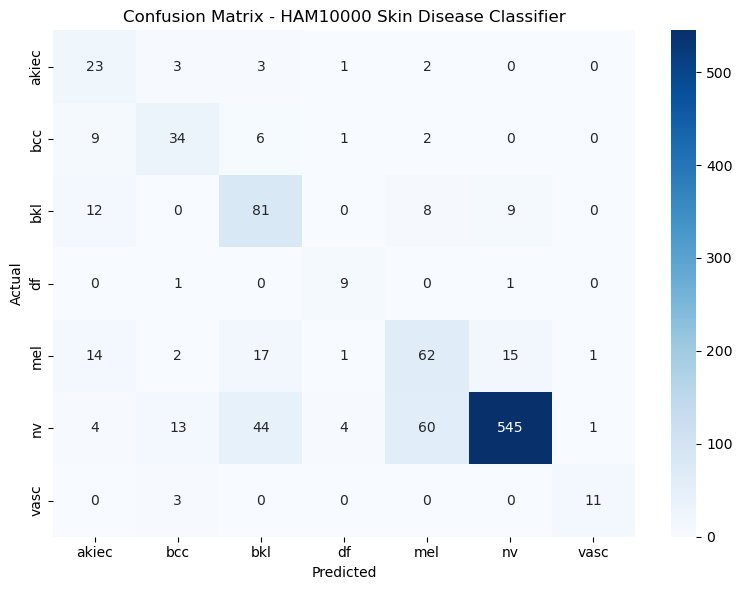

In [13]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - HAM10000 Skin Disease Classifier")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [14]:
torch.save({
    'model_state_dict': model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx,
    'val_acc': best_val_acc
}, "model_phase2_76acc.pt")

In [15]:
import copy
import torch.optim as optim

# Reload Phase 2 best as starting point
model = models.efficientnet_b0(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)
model.load_state_dict(best_model_wts)

# Unfreeze one more block (no dropout this time)
for param in model.features[-3:].parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

EPOCHS_PHASE3 = 8
patience = 3
epochs_no_improve = 0

for epoch in range(EPOCHS_PHASE3):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step(val_loss)
    print(f"[Phase3] Epoch {epoch+1}/{EPOCHS_PHASE3} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

model.load_state_dict(best_model_wts)
print(f"Final best val acc: {best_val_acc:.4f}")

[Phase3] Epoch 1/8 | Train Loss: 0.4029 Acc: 0.8517 | Val Loss: 0.6240 Acc: 0.7712
[Phase3] Epoch 2/8 | Train Loss: 0.3338 Acc: 0.8792 | Val Loss: 0.6420 Acc: 0.7772
[Phase3] Epoch 3/8 | Train Loss: 0.2962 Acc: 0.8918 | Val Loss: 0.5803 Acc: 0.7832
[Phase3] Epoch 4/8 | Train Loss: 0.2707 Acc: 0.9063 | Val Loss: 0.5234 Acc: 0.8192
[Phase3] Epoch 5/8 | Train Loss: 0.2427 Acc: 0.9130 | Val Loss: 0.5105 Acc: 0.8092
[Phase3] Epoch 6/8 | Train Loss: 0.2197 Acc: 0.9259 | Val Loss: 0.4764 Acc: 0.8242
[Phase3] Epoch 7/8 | Train Loss: 0.1947 Acc: 0.9329 | Val Loss: 0.4878 Acc: 0.8152
[Phase3] Epoch 8/8 | Train Loss: 0.1797 Acc: 0.9342 | Val Loss: 0.4645 Acc: 0.8222
Final best val acc: 0.8242


In [16]:
print(best_val_acc)

0.8241758241758241


In [17]:
print(best_model_wts)

OrderedDict({'features.0.0.weight': tensor([[[[ 1.2380e-01,  6.5806e-01,  4.5857e-01],
          [-1.0844e-01, -6.0829e-01, -3.3187e-01],
          [ 3.0127e-02, -1.0145e-01, -1.0174e-01]],

         [[ 6.5384e-02,  1.6565e+00,  1.7449e+00],
          [-1.3439e-01, -1.5353e+00, -1.5924e+00],
          [ 5.1799e-02, -1.1234e-01, -1.2487e-01]],

         [[ 8.8684e-02,  3.6216e-01,  2.7053e-01],
          [-1.1771e-01, -2.8017e-01, -2.1778e-01],
          [ 3.8232e-02, -6.9713e-02, -8.1098e-02]]],


        [[[ 1.6615e-01, -1.9867e-01,  8.4920e-02],
          [ 8.9183e-01, -1.2092e+00,  2.7785e-01],
          [ 1.0757e+00, -1.2585e+00,  2.0811e-01]],

         [[ 3.2940e-01, -4.3315e-01,  1.8914e-01],
          [ 1.6225e+00, -2.1176e+00,  4.1145e-01],
          [ 1.7242e+00, -2.0744e+00,  3.4078e-01]],

         [[ 9.5766e-02, -1.5905e-01,  7.5197e-02],
          [ 8.0572e-01, -9.6973e-01,  2.6338e-01],
          [ 7.2005e-01, -1.0021e+00,  1.9908e-01]]],


        [[[ 5.4720e-02,  2.651

In [19]:
model.load_state_dict(best_model_wts)
print(f"Final best val acc: {best_val_acc:.4f}")

Final best val acc: 0.8242


              precision    recall  f1-score   support

       akiec       0.63      0.75      0.69        32
         bcc       0.75      0.83      0.79        52
         bkl       0.62      0.75      0.68       110
          df       0.91      0.91      0.91        11
         mel       0.56      0.71      0.63       112
          nv       0.96      0.87      0.91       671
        vasc       0.80      0.86      0.83        14

    accuracy                           0.83      1002
   macro avg       0.75      0.81      0.78      1002
weighted avg       0.86      0.83      0.84      1002



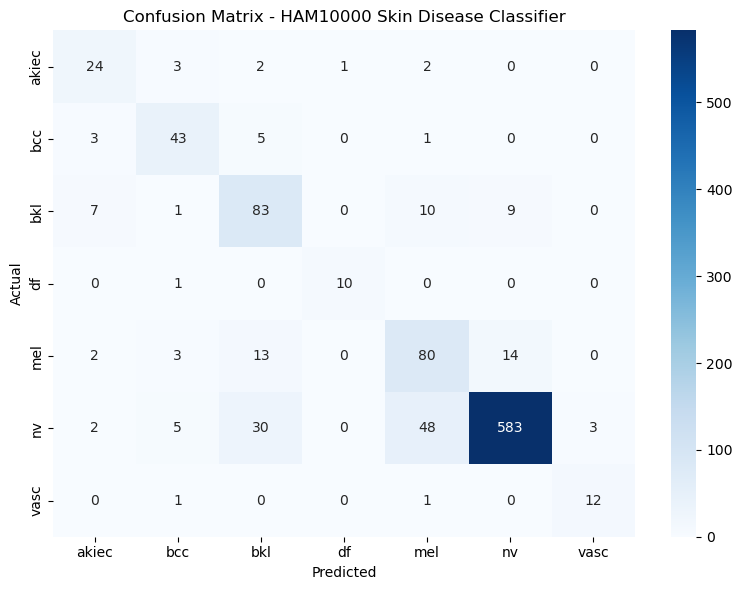

In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - HAM10000 Skin Disease Classifier")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [21]:
torch.save({
    'model_state_dict': model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx,
    'val_acc': best_val_acc,
    'test_acc': 0.83
}, "model.pt")

print("Saved model.pt")
print("Class mapping:", train_dataset.class_to_idx)

Saved model.pt
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
